# Day 05 - ANN人工神经网络

## 学习目标
- 了解学习率衰减策略
- 掌握正则化方法
- 掌握神经网络训练的一般工作流
- 实现手机价格分类案例

In [1]:
# 导包
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei']  # 微软雅黑
plt.rcParams['axes.unicode_minus'] = False            # 解决负号显示问题
# 设置设备
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print(f"当前设备：{DEVICE}")

当前设备：cuda


## 1.神经网络理论串讲

神经网络训练的一般工作流：
- 1.准备数据集
- 2.搭建神经网络模型
- 3.模型训练
    1. 前向传播：$y\_pred = model(X)$
    2. 计算损失：$loss = loss\_fn(y\_pred, y)$
    3. 梯度清零：$optimizer.zero\_grad()$
    4. 反向传播：$loss.backward()$
    5. 更新参数：$optimizer.step()$
- 4.模型测试

![串讲](../06-每日一图/day05_神经网络串讲.png)

### 1.1 计算神经网络的网络参数量

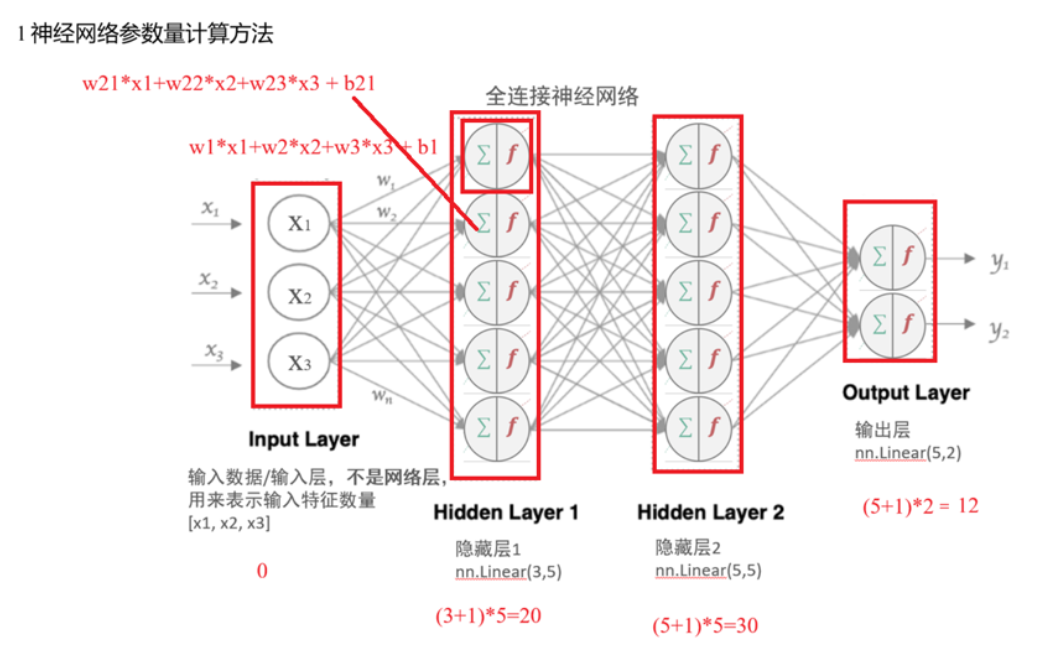

全连接/线性网络层参数量计算公式：
- (输入维度+1)*输出维度


### 1.2 激活函数

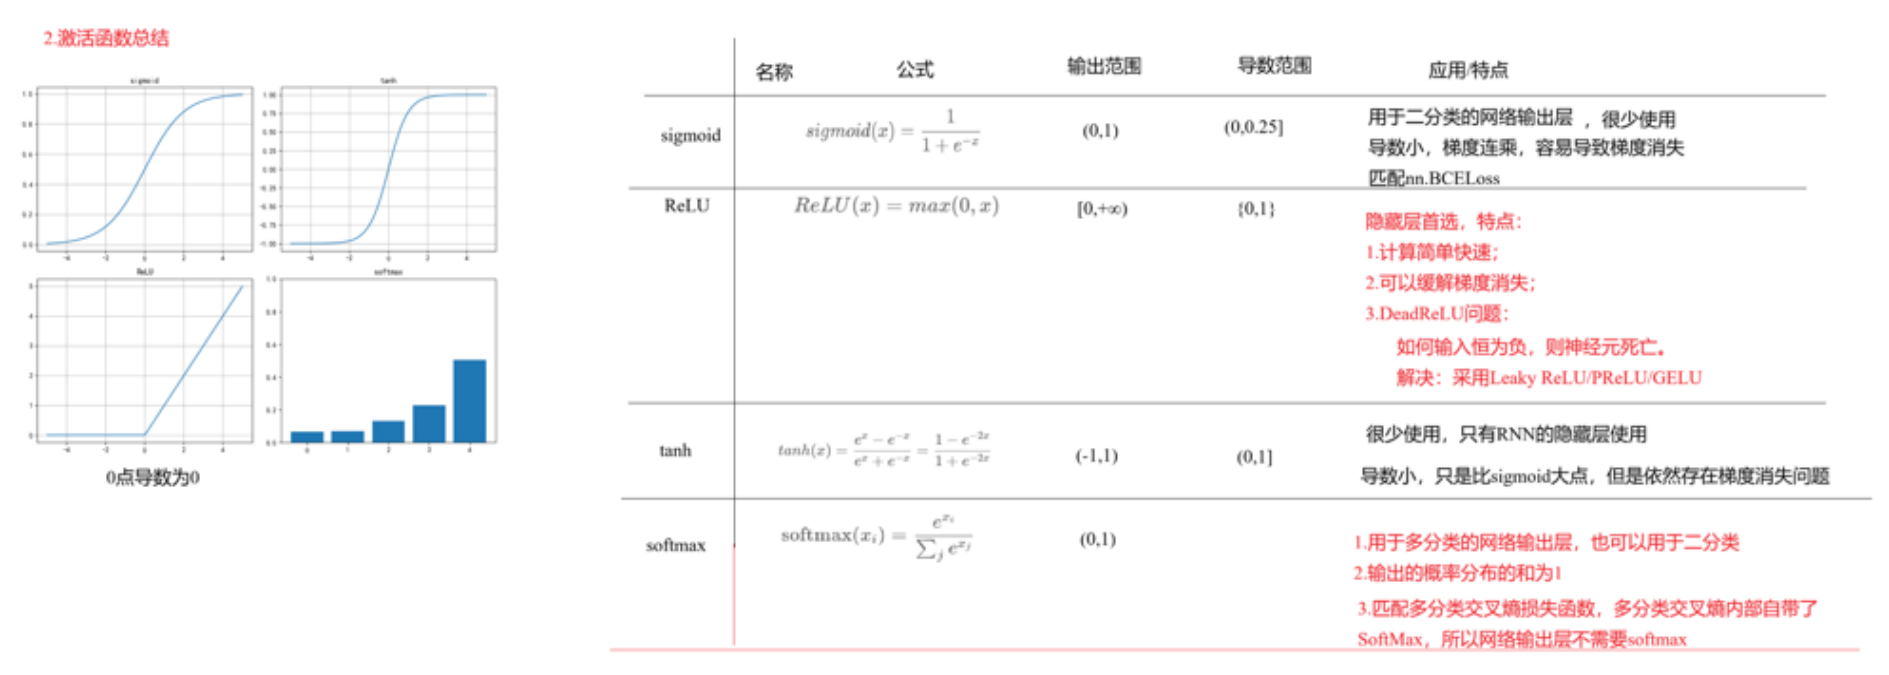

1.网络层如何选择激活函数
- 隐藏层：ReLU, PReLU/leaky relu, (tanh, sigmoid)
- 输出层
    - 分类：softmax(多分类+二分类)，sigmoid(二分类)
    - 回归：identity(没有激活函数)，范围ReLU,sigmoid,tanh

### 1.3 损失函数

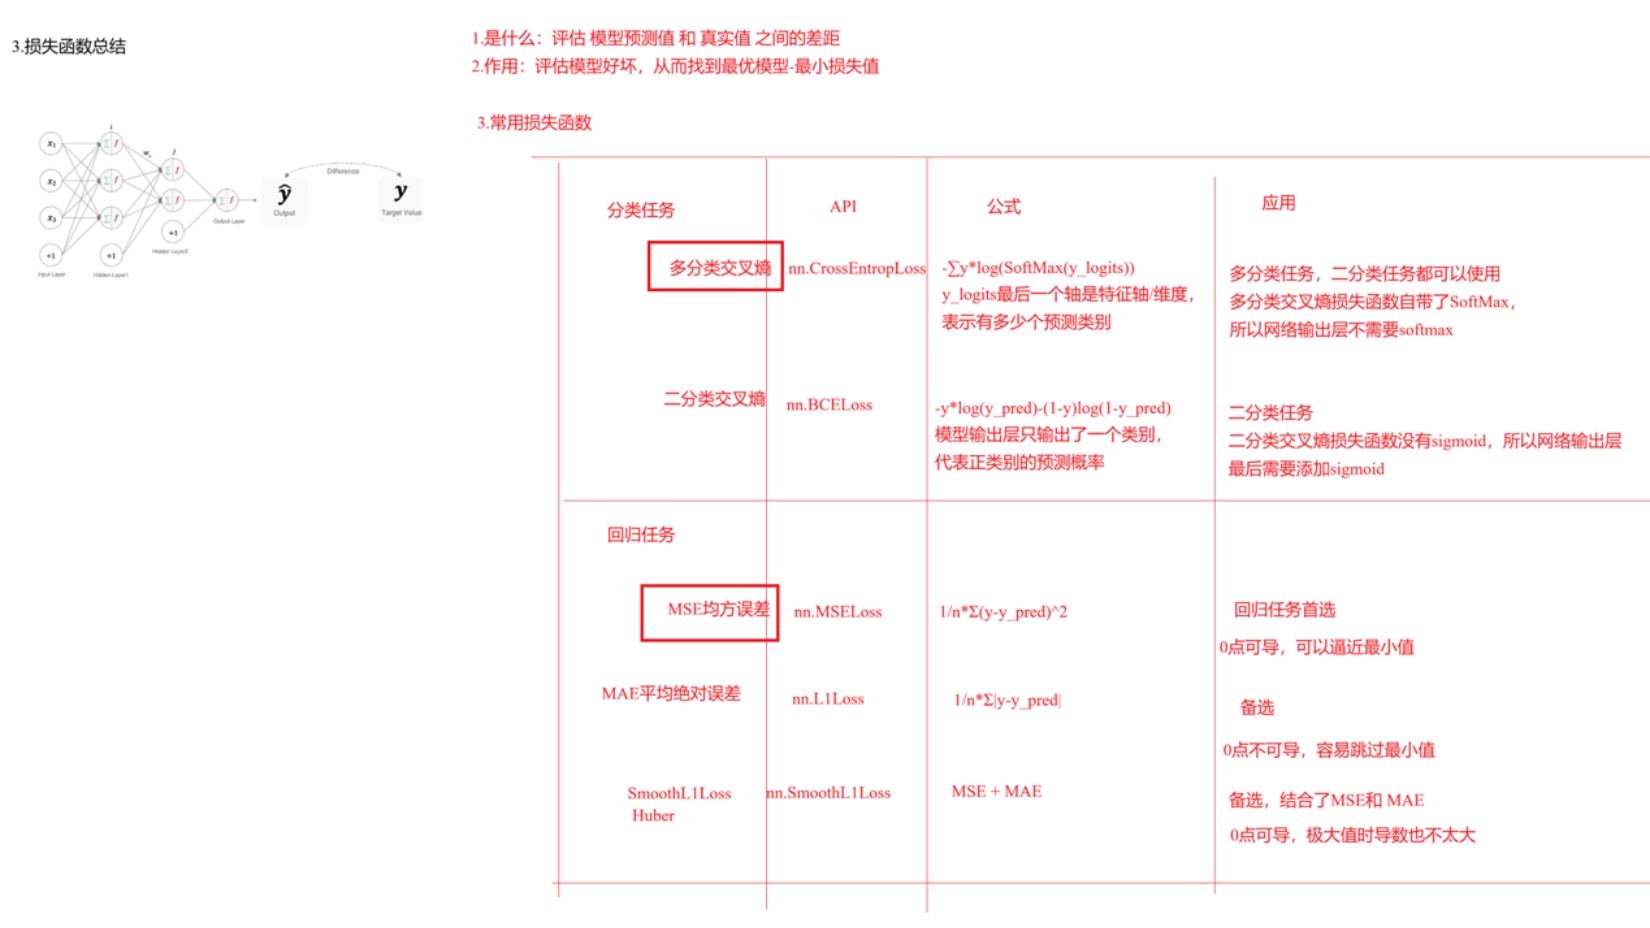

如何选择损失函数
- 分类任务：
    - 多分类：多分类交叉熵
    - 二分类：二分类交叉熵/多分类交叉熵
- 回归任务：
  - MSE
  - MAE
  - SmoothL1/Huber


### 1.4 反向传播

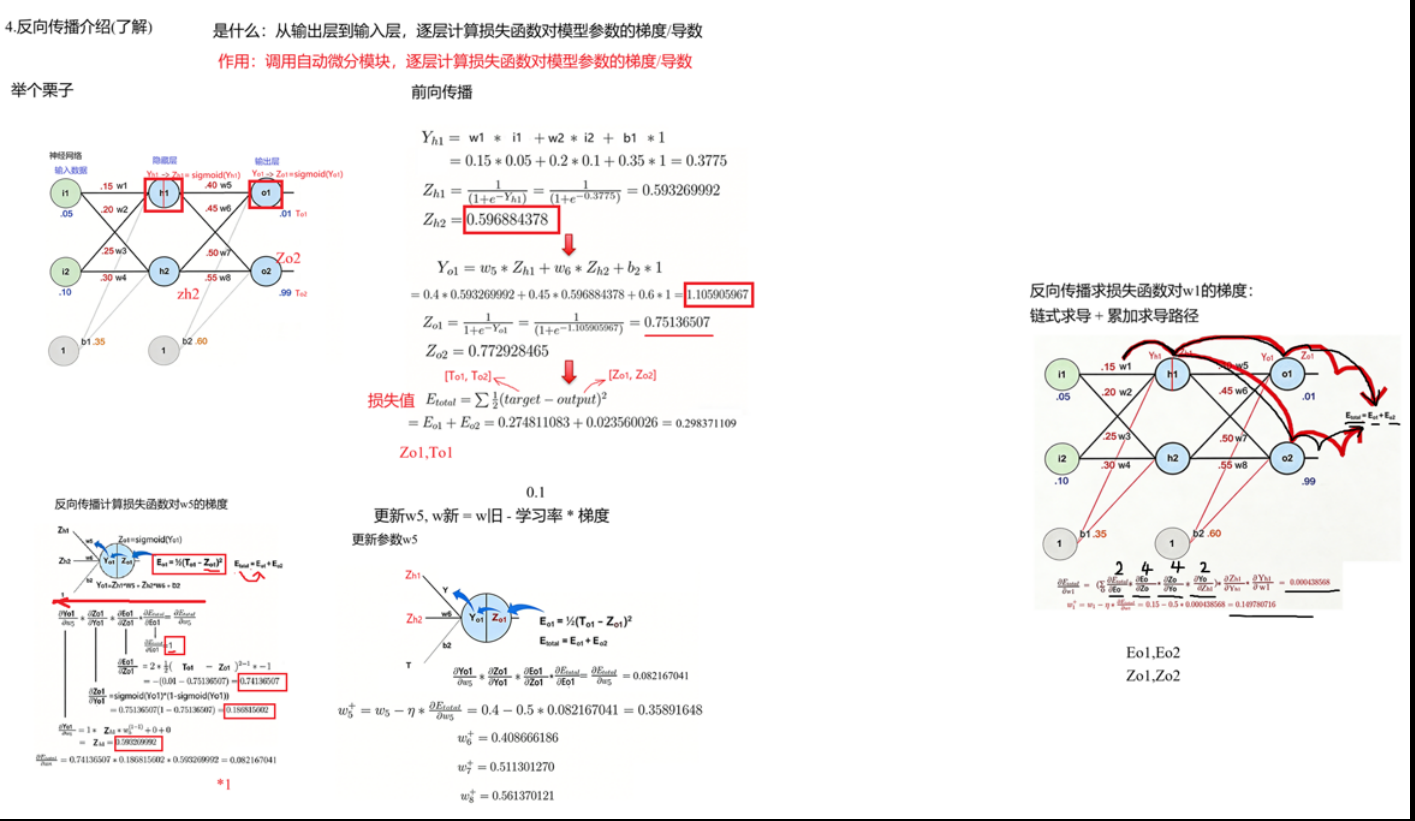

反向传播的步骤：
1. 前向传播，计算预测值与损失值
2. 从输出层到输入层，用链式法则，逐层计算损失对所有参数的梯度/导数
3. 根据梯度下降法，更新模型参数

### 1.5 梯度下降法的优化方法

为什么要优化梯度下降法-梯度下降法的问题

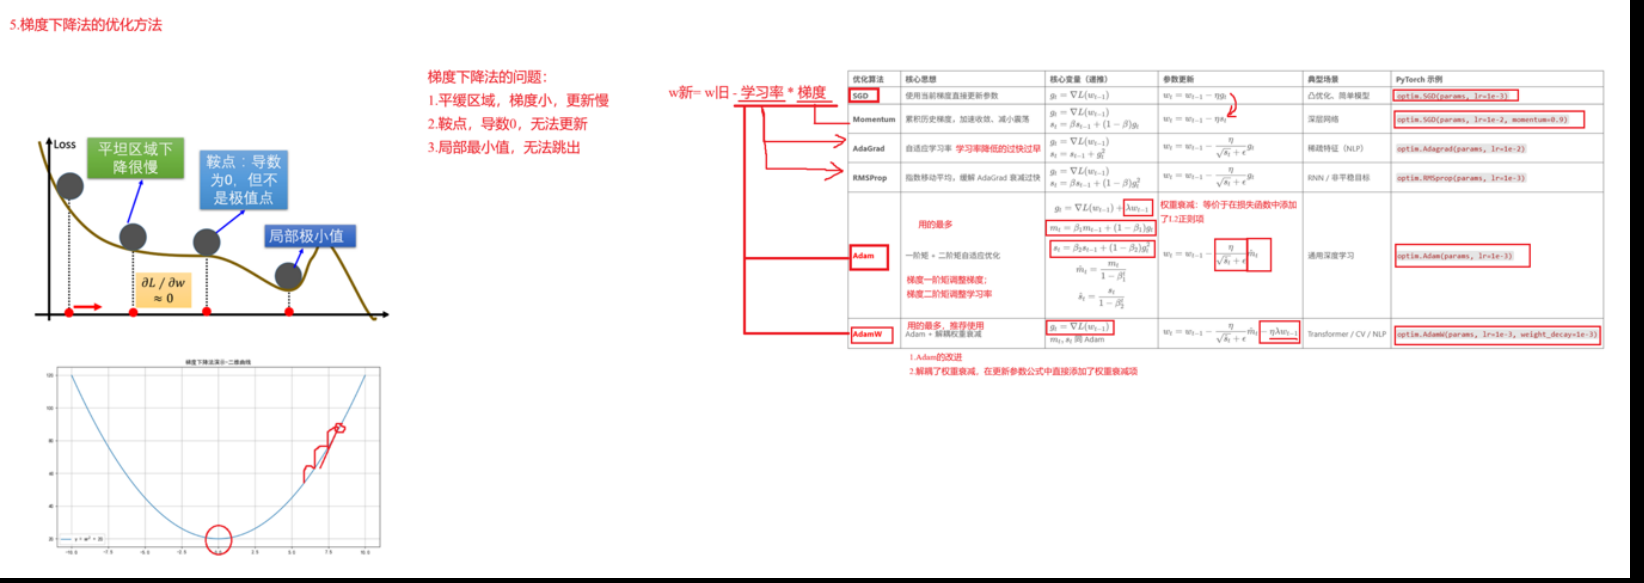

梯度下降法的问题：
1. 平缓区域，梯度小，更新慢
2. 鞍点，无法更新
3. 局部最优解，无法跳出



如何选择优化方法

- Adam/AdamW(推荐) > RMSprop > 动量法Momentum > 原始SGD，AdaGrad(不建议)

梯度下降法优化方法对比

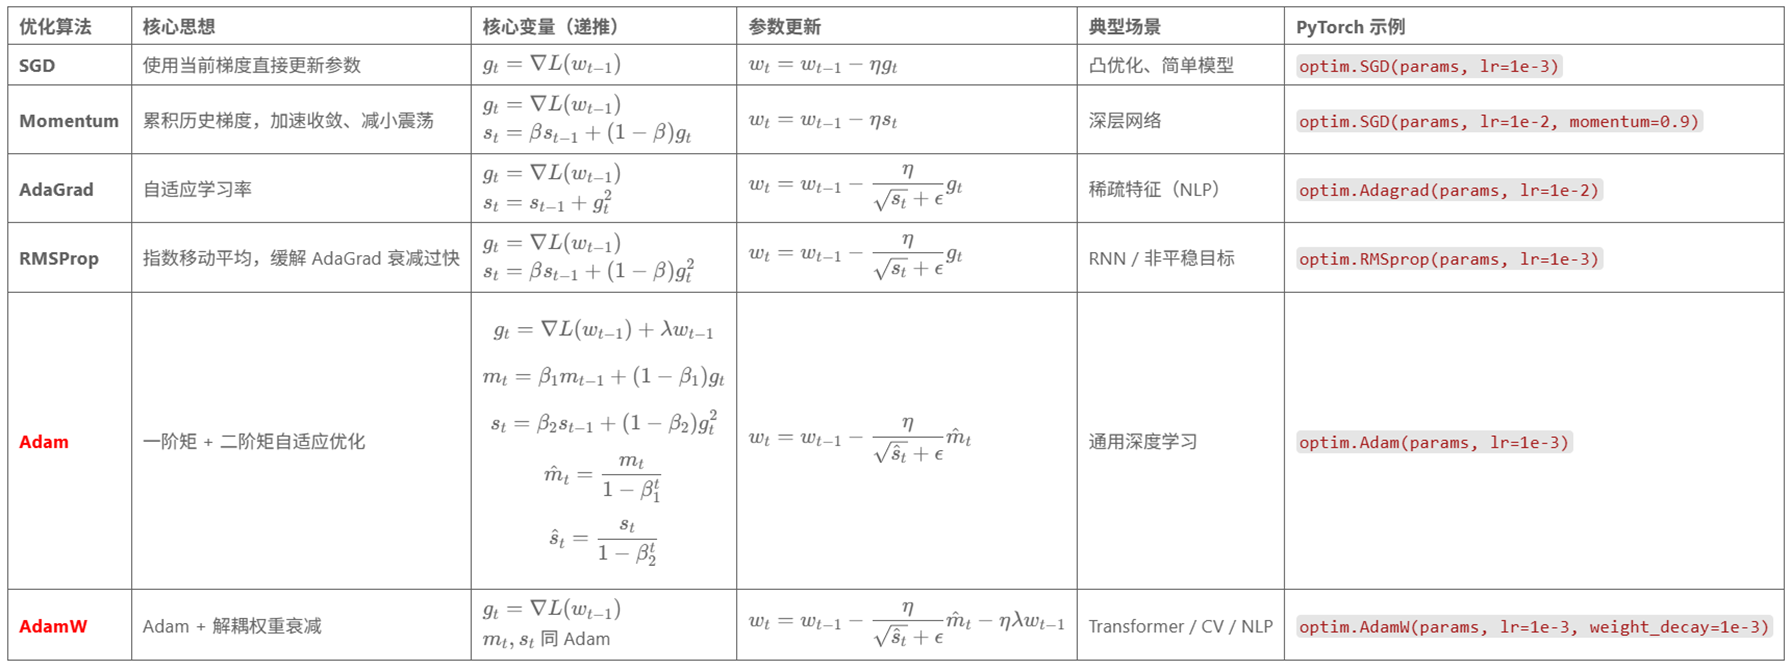

梯度下降法优化方法总结
1. SGD原始梯度下降法：optim.SGD, 使用当前梯度直接更新参数，用于凸优化问题，容易陷入局部最优解
2. 动量法Momentum: optim.SGD(momentum=0.9), 引入动量概念，利用历史梯度信息，加速收敛
3. AdaGrad: optim.Adagrad, 自动调整学习率，学习率下降过快过早，导致模型更新慢
4. RMSprop: optim.RMSprop, 自动调整学习率，对AdaGrad的改进
5. Adam: optim.Adam, 结合 动量法和RMSprop，同时调整学习率和梯度，训练稳定
6. AdamW: optim.AdamW, 对Adam的改进，解决权重衰减问题，推荐使用

## 2.学习率衰减策略

学习率对梯度下降路径的影响

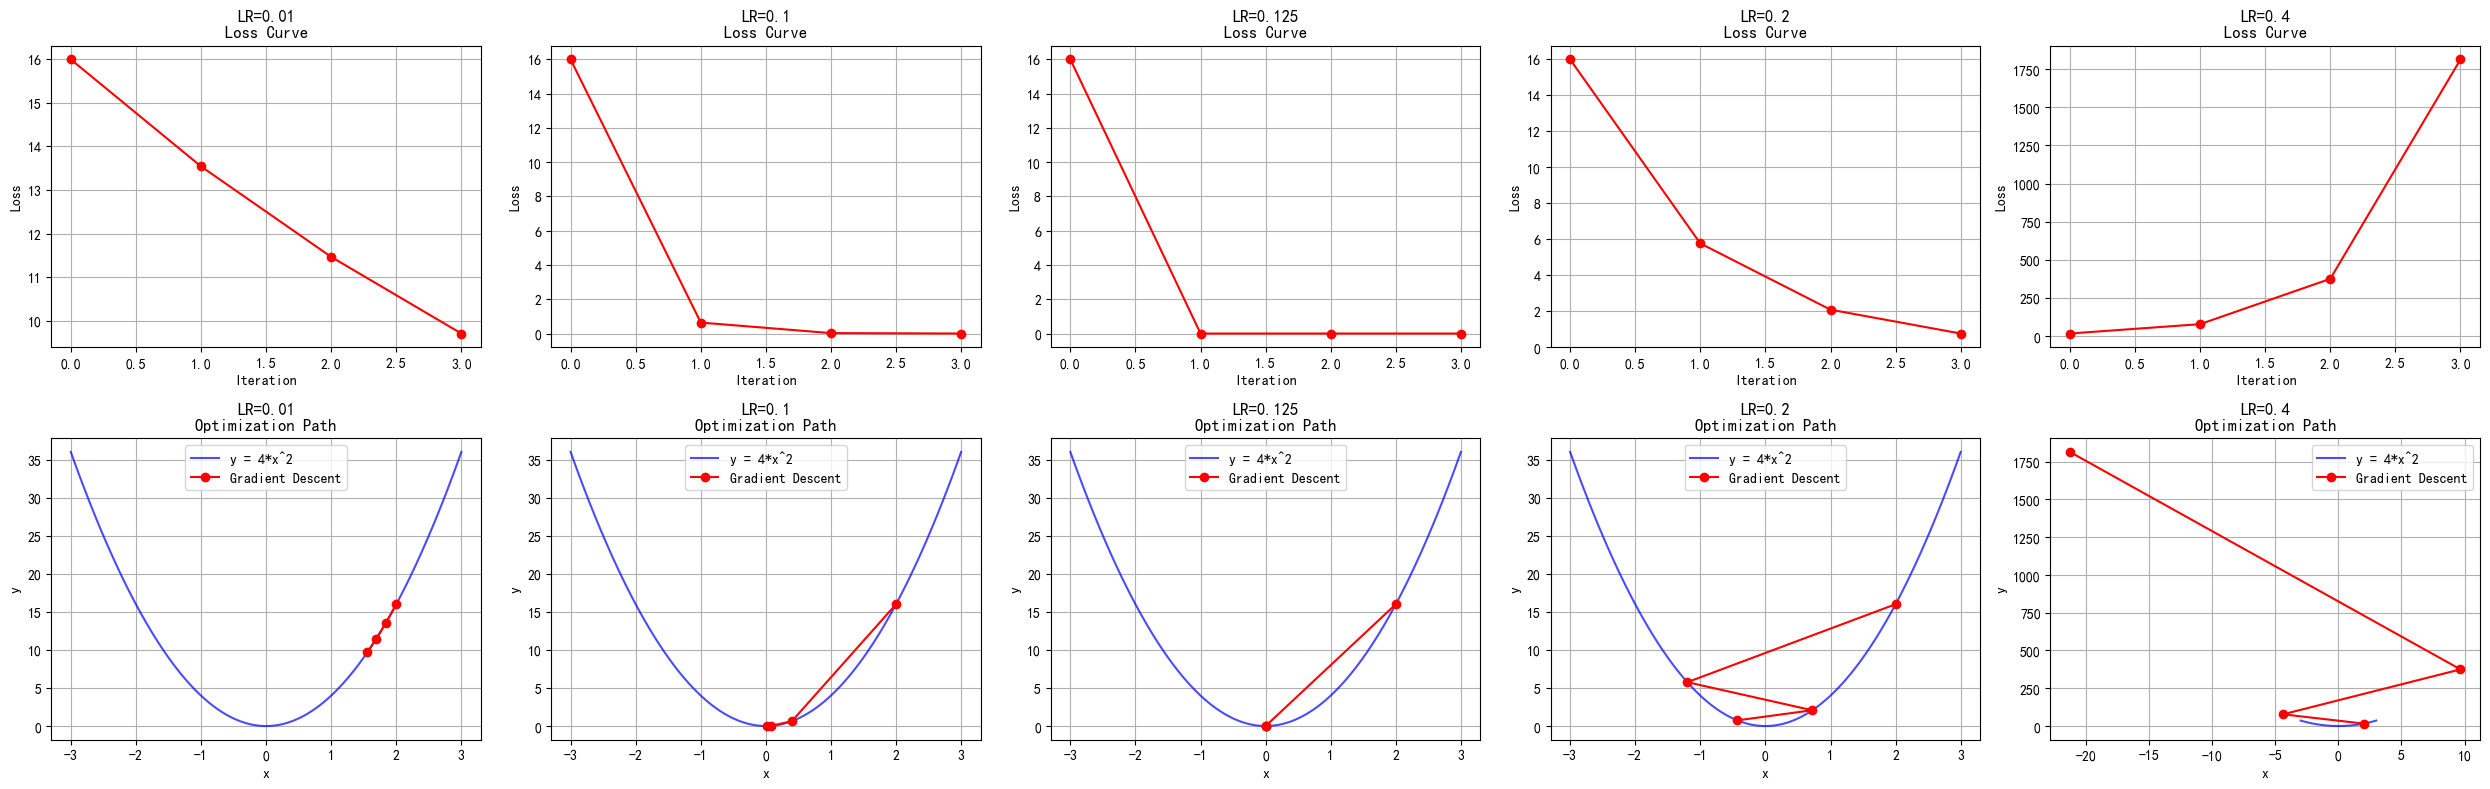

In [2]:
import torch
import matplotlib.pyplot as plt

def func(x_t):
    return torch.pow(2*x_t, 2)  # y = 4 x ^2

# 采用较小的学习率，梯度下降的速度慢
# 采用较大的学习率，梯度下降太快越过了最小值点，导致不收敛，甚至震荡
def demo01():
    # 定义不同的学习率进行实验
    learning_rates = [0.01, 0.1, 0.125, 0.2, 0.4]
    max_iteration = 4

    # 创建图像和子图
    fig, axes = plt.subplots(2, len(learning_rates), figsize=(5 * len(learning_rates), 8))

    for idx, lr in enumerate(learning_rates):
        # 重置参数
        x = torch.tensor([2.], requires_grad=True)
        iter_rec, loss_rec, x_rec = list(), list(), list()

        # 梯度下降过程
        for i in range(max_iteration):
            y = func(x)
            y.backward()

            x_rec.append(x.item())
            x.data.sub_(lr * x.grad)
            x.grad.zero_()

            iter_rec.append(i)
            loss_rec.append(y.item())

        # 绘制损失曲线
        axes[0, idx].plot(iter_rec, loss_rec, '-ro')
        axes[0, idx].set_title(f'LR={lr}\nLoss Curve')
        axes[0, idx].set_xlabel("Iteration")
        axes[0, idx].set_ylabel("Loss")
        axes[0, idx].grid(True)

        # 绘制函数曲线和下降轨迹
        x_t = torch.linspace(-3, 3, 100)
        y_t = func(x_t)
        axes[1, idx].plot(x_t.detach().numpy(), y_t.detach().numpy(), 'b-', alpha=0.7, label="y = 4*x^2")

        y_rec = [func(torch.tensor(i)).item() for i in x_rec]
        axes[1, idx].plot(x_rec, y_rec, '-ro', label="Gradient Descent")
        axes[1, idx].set_title(f'LR={lr}\nOptimization Path')
        axes[1, idx].set_xlabel("x")
        axes[1, idx].set_ylabel("y")
        axes[1, idx].grid(True)
        axes[1, idx].legend()

    plt.tight_layout()
    # plt.show()
# 测试
if __name__ == '__main__':
    demo01()

学习率大小对梯度下降路径的影响：

1. 学习率小，梯度下降慢
2. 学习率大，梯度下降快
3. 学习率过大，可能导致梯度震荡或爆炸

在训练神经网络时，一般情况下学习率都会随着训练而变化。在神经网络训练的后期，如果**学习率过高，会造成loss的振荡**，但是如果**学习率减小的过慢，又会造成收敛变慢**。

###  等间隔学习率衰减 optim.lr_scheduler.StepLR

固定步长衰减

###  指定间隔学习率衰减 optim.lr_scheduler.MultiStepLR

指定步长衰减

### 指数学习率衰减 optim.lr_scheduler.ExponentialLR
按照指数衰减，本轮的学习率 = 上一轮的学习率 * 衰减系数

### 余弦退火学习率调度策略
- torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_0, T_mult=1, eta_min=0, last_epoch=-1)
- torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0, T_mult=1, eta_min=0, last_epoch=-1)

余弦退火（Cosine Annealing）学习率调度公式：

$$
\eta_t = \eta_{\min} + \frac{1}{2} (\eta_{\max} - \eta_{\min}) 
\Bigg( 1 + \cos\Big(\frac{t \pi}{T_{\max}}\Big) \Bigg)
$$

其中：

- $\eta_t$ ：第 $t$ 步的学习率  
- $\eta_{\min}$ ：最小学习率  
- $\eta_{\max}$ ：初始/最大学习率  
- $T_{\max}$ ：一个周期的总步数
- $t$ ：当前步数（或 epoch 数），$0 \le t \le T_{\max}$


C:\Users\angmi\AppData\Local\Temp\ipykernel_35532\3393194986.py:88: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


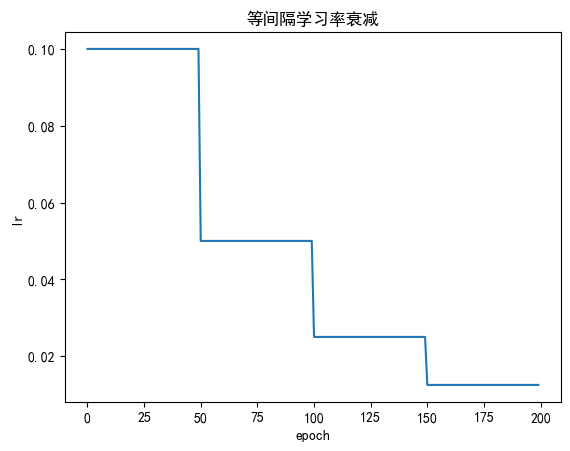

C:\Users\angmi\AppData\Local\Temp\ipykernel_35532\3393194986.py:134: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


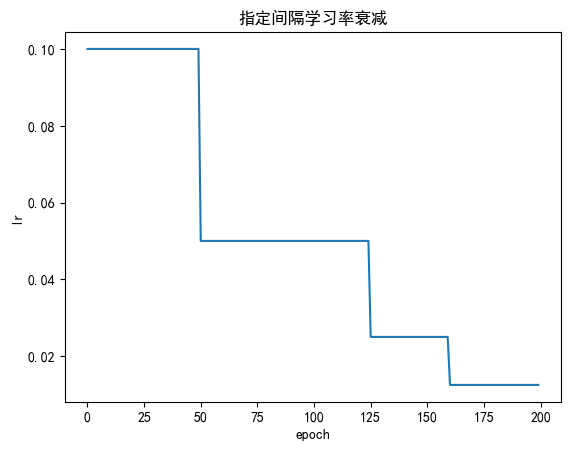

C:\Users\angmi\AppData\Local\Temp\ipykernel_35532\3393194986.py:182: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


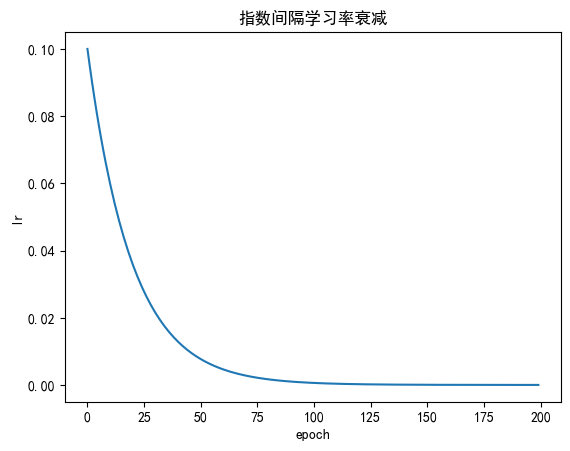

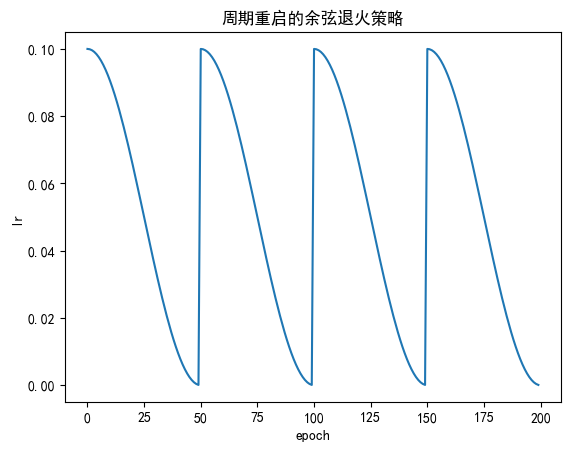

In [3]:
"""
演示
    学习率衰减策略/学习率调度策略
介绍：
    之前学的优化器，可以调节学习率：Adam/AdamW, AdaGrad, RMSProp,
    Momentum(调节梯度)
    也可以手动调节学习率：
        等间隔学习率衰减
        指定间隔学习率衰减
        指数间隔学习率衰减
        周期重启的余弦退火策略
等间隔学习率衰减
    固定间隔来衰减学习率，当前学习率lr = 上一次的学习率lr*γ, 比如γ=0.5

指定间隔学习率衰减
    人为指定间隔来衰减学习率，当前学习率lr = 上一次的学习率lr*γ, 比如γ=0.5

指数间隔学习率衰减
    当前轮次的lr = 上个轮次lr*γ, 比如γ=0.95

周期重启的余弦退火策略
    带有周期重启的余弦曲线，可以让学习率重新启动，有可能冲过局部最小值

神经网络的训练流程：
    1.准备数据集
    2.构建神经网络模型
    3.设置损失函数和优化器，以及学习率调度器
    4.模型训练
        1.前向传播
        2.计算损失
        3.梯度清零
        4.反向传播
        5.更新参数:w新 = w旧-学习率*梯度
        6.更新学习率
    5.模型测试

需要掌握：
    无

"""


# 导包
import torch
import torch.nn as nn
import torch.optim as optim # 优化器模块，提供各种优化器对象，比如SGD,Adam
import matplotlib.pyplot as plt # 绘图
# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei']  # 微软雅黑
plt.rcParams['axes.unicode_minus'] = False            # 解决负号显示问题

# 1.定义函数，演示 等间隔学习率衰减策略
def demo01():
    # 0.初始化参数
    lr = 0.1
    epochs = 200
    iteration = 10
    # 1.准备数据集
    x = torch.tensor([1.0],dtype=torch.float32)
    y_true = torch.tensor([0.0],dtype=torch.float32)
    # 2.构建神经网络模型
    # 创建张量，模拟网络参数
    w = torch.tensor([1.0],dtype=torch.float32,requires_grad=True)
    # 3.设置损失函数和优化器，以及学习率调度器
    # 损失函数
    loss_fn = nn.MSELoss()
    # 优化器
    optimizer = optim.SGD([w],lr=lr)
    # 学习率调度器
    scheduler = optim.lr_scheduler.StepLR(optimizer,step_size=50,gamma=0.5)
    # 4.模型训练
    # 定义列表，记录训练轮数和学习率
    lr_list = []
    epoch_list = []
    for epoch in range(epochs):
        # 0.获取当前轮数 和 学习率，保存到记录列表中
        epoch_list.append(epoch)
        lr_list.append(scheduler.get_last_lr()[0])
        # 遍历批次
        for i in range(iteration):
            # 1.前向传播
            y_pred = w * x
            # 2.计算损失
            # 3.梯度清零
            # 4.反向传播
            # 5.更新参数:w新 = w旧-学习率*梯度
        # 6.更新学习率
        scheduler.step()
    # 5.可视化学习率变化
    plt.plot(epoch_list,lr_list)
    plt.title("等间隔学习率衰减")
    plt.xlabel("epoch")
    plt.ylabel("lr")
    plt.show()

# 2.定义函数，演示 指定间隔学习率衰减策略
def demo02():
    # 0.初始化参数
    lr = 0.1
    epochs = 200
    iteration = 10
    # 1.准备数据集
    x = torch.tensor([1.0],dtype=torch.float32)
    y_true = torch.tensor([0.0],dtype=torch.float32)
    # 2.构建神经网络模型
    # 创建张量，模拟网络参数
    w = torch.tensor([1.0],dtype=torch.float32,requires_grad=True)
    # 3.设置损失函数和优化器，以及学习率调度器
    # 损失函数
    loss_fn = nn.MSELoss()
    # 优化器
    optimizer = optim.SGD([w],lr=lr)
    # 学习率调度器
    # scheduler = optim.lr_scheduler.StepLR(optimizer,step_size=50,gamma=0.5)
    # 指定间隔学习率衰减策略
    scheduler = optim.lr_scheduler.MultiStepLR(optimizer,milestones=[50,125,160],gamma=0.5)
    # 4.模型训练
    # 定义列表，记录训练轮数和学习率
    lr_list = []
    epoch_list = []
    for epoch in range(epochs):
        # 0.获取当前轮数 和 学习率，保存到记录列表中
        epoch_list.append(epoch)
        lr_list.append(scheduler.get_last_lr()[0])
        # 遍历批次
        for i in range(iteration):
            # 1.前向传播
            y_pred = w * x
            # 2.计算损失
            # 3.梯度清零
            # 4.反向传播
            # 5.更新参数:w新 = w旧-学习率*梯度
        # 6.更新学习率
        scheduler.step()
    # 5.可视化学习率变化
    plt.plot(epoch_list,lr_list)
    plt.title("指定间隔学习率衰减")
    plt.xlabel("epoch")
    plt.ylabel("lr")
    plt.show()

# 3.定义函数，演示 指数间隔学习率衰减策略
def demo03():
    # 0.初始化参数
    lr = 0.1
    epochs = 200
    iteration = 10
    # 1.准备数据集
    x = torch.tensor([1.0],dtype=torch.float32)
    y_true = torch.tensor([0.0],dtype=torch.float32)
    # 2.构建神经网络模型
    # 创建张量，模拟网络参数
    w = torch.tensor([1.0],dtype=torch.float32,requires_grad=True)
    # 3.设置损失函数和优化器，以及学习率调度器
    # 损失函数
    loss_fn = nn.MSELoss()
    # 优化器
    optimizer = optim.SGD([w],lr=lr)
    # 学习率调度器
    # scheduler = optim.lr_scheduler.StepLR(optimizer,step_size=50,gamma=0.5)
    # 指定间隔学习率衰减策略
    # scheduler = optim.lr_scheduler.MultiStepLR(optimizer,milestones=[50,125,160],gamma=0.5)
    # 指数间隔学习率衰减策略
    scheduler = optim.lr_scheduler.ExponentialLR(optimizer,gamma=0.95)
    # 4.模型训练
    # 定义列表，记录训练轮数和学习率
    lr_list = []
    epoch_list = []
    for epoch in range(epochs):
        # 0.获取当前轮数 和 学习率，保存到记录列表中
        epoch_list.append(epoch)
        lr_list.append(scheduler.get_last_lr()[0])
        # 遍历批次
        for i in range(iteration):
            # 1.前向传播
            y_pred = w * x
            # 2.计算损失
            # 3.梯度清零
            # 4.反向传播
            # 5.更新参数:w新 = w旧-学习率*梯度
        # 6.更新学习率
        scheduler.step()
    # 5.可视化学习率变化
    plt.plot(epoch_list,lr_list)
    plt.title("指数间隔学习率衰减")
    plt.xlabel("epoch")
    plt.ylabel("lr")
    plt.show()

# 4.定义函数，演示 周期重启的余弦退火策略
def demo04():
    # 0.初始化参数
    lr = 0.1
    epochs = 200
    iteration = 10
    # 1.准备数据集
    x = torch.tensor([1.0],dtype=torch.float32)
    y_true = torch.tensor([0.0],dtype=torch.float32)
    # 2.构建神经网络模型
    # 创建张量，模拟网络参数
    w = torch.tensor([1.0],dtype=torch.float32,requires_grad=True)
    # 3.设置损失函数和优化器，以及学习率调度器
    # 损失函数
    loss_fn = nn.MSELoss()
    # 优化器
    optimizer = optim.SGD([w],lr=lr)
    # 学习率调度器
    # scheduler = optim.lr_scheduler.StepLR(optimizer,step_size=50,gamma=0.5)
    # 指定间隔学习率衰减策略
    # scheduler = optim.lr_scheduler.MultiStepLR(optimizer,milestones=[50,125,160],gamma=0.5)
    # 指数间隔学习率衰减策略
    # scheduler = optim.lr_scheduler.ExponentialLR(optimizer,gamma=0.95)
    # 周期重启的余弦退火策略
    scheduler = optim.lr_scheduler.CosineAnnealingWarmRestarts(
        optimizer,  # 优化器对象
        T_0=50, # 第一个周期的轮数
        eta_min=0
    )
    # 4.模型训练
    # 定义列表，记录训练轮数和学习率
    lr_list = []
    epoch_list = []
    for epoch in range(epochs):
        # 0.获取当前轮数 和 学习率，保存到记录列表中
        epoch_list.append(epoch)
        lr_list.append(scheduler.get_last_lr()[0])
        # 遍历批次
        for i in range(iteration):
            # 1.前向传播
            y_pred = w * x
            # 2.计算损失
            # 3.梯度清零
            # 4.反向传播
            # 5.更新参数:w新 = w旧-学习率*梯度
        # 6.更新学习率
        scheduler.step()
    # 5.可视化学习率变化
    plt.plot(epoch_list,lr_list)
    plt.title("周期重启的余弦退火策略")
    plt.xlabel("epoch")
    plt.ylabel("lr")
    plt.show()

# 测试
if __name__ == '__main__':
    demo01()
    demo02()
    demo03()
    demo04()

| 方法 | 衰减方式 | 适用场景 | PyTorch API |
|------|----------|----------|-------------|
| 等间隔衰减 (Step Decay) | 固定步长衰减 | 简单任务 | `torch.optim.lr_scheduler.StepLR` |
| 指定间隔衰减 (MultiStep Decay) | 指定间隔衰减 | 简单任务 | `torch.optim.lr_scheduler.MultiStepLR` |
| 指数衰减 (Exponential Decay) | 指数比例衰减 | 简单任务 | `torch.optim.lr_scheduler.ExponentialLR` |
| **周期重启的余弦退火 (Cosine Annealing Warm Restarts)** | **周期性余弦下降并重启** | **复杂非凸优化、易陷局部极小值的任务** | **`torch.optim.lr_scheduler.CosineAnnealingWarmRestarts`** |

## 3.正则化方法

###  什么是正则化

![05-01](assets/05-01.png)

- 在设计机器学习算法时希望在新样本上的泛化能力强。许多机器学习算法都采用相关的策略来减小测试误差，这些策略被统称为正则化
- 神经网络强大的表示能力经常遇到过拟合，所以需要使用不同形式的正则化策略
- 目前在深度学习中使用较多的策略有范数惩罚，DropOut，特殊的网络层等，接下来我们对其进行详细的介绍

### L1与L2正则化

L1和L2正则化通过在损失函数上添加惩罚项来实现。

| 内容 | L1 正则化（Lasso） | L2 正则化（Ridge / 权重衰减） |
|------|----------------------|----------------------------------|
| **公式** | $loss = loss + λ \sum \|w\|$ | $loss = loss + \frac{λ}{2} \sum w^2$ |
| **核心特点** | 稀疏解、特征选择、鲁棒性强 | 权重衰减、平滑解、稳定性高 |
| **适用场景** | 高维特征选择、模型压缩 | 深度学习防过拟合、数值稳定 |


###  Dropout正则化

在训练深层神经网络时，由于模型参数较多，在数据量不足的情况下，很容易过拟合。Dropout 随机失活 是一个简单有效的正则化方法。

![image-20220517141847967](assets/image-20220517141847967.png)

- 在训练过程中，Dropout的实现是**让神经元以超参数p（丢弃概率）的概率停止工作或者激活被置为0,未被置为0的进行缩放，缩放比例为1/(1-p)**。训练过程可以认为是对完整的神经网络的一些子集进行训练，每次只更新子网络的参数
- 在实际应用中，Dropout参数丢弃概率p通常取值在0.2到0.5之间
  - 对于较小的模型或较复杂的任务，丢弃概率p可以选择0.3或更小
  - 对于非常深的网络，较大的丢弃概率p（如0.5或0.6）可能会有效防止过拟合
  - 实际应用中，通常会在全连接层（激活函数后）之后添加Dropout层
- **在测试过程中，随机失活不起作用**
  - 在测试阶段，使用所有的神经元进行预测，以获得更稳定的结果
  - 直接使用训练好的模型进行测试，由于所有的神经元都参与计算，输出的期望值会比训练阶段高。测试阶段的期望输出是 E[x_test] = x
  - 测试/推理模式：==model.eval()==
- **缩放的必要性**
  - 在训练阶段，将参与计算的神经元的输出除以(1-p)
  - 经过Dropout后的期望输出变为 E[x_dropout] = [(1-p) * x] / (1-p) = x，与测试阶段的期望输出一致
  - 训练模型：==model.train()==

In [4]:
# 导包
import torch
import torch.nn as nn

# 1.定义函数，演示 dropout随机失活
def demo01():
    # 0.设置随机种子
    torch.manual_seed(28)
    # 1.创建输入数据，(batch_size,input_dim)
    x = torch.randint(0,10,(1,5),dtype=torch.float32)
    print(f"x: {x},x.shape: {x.shape}")
    # 2.创建神经网络，一个简单的线性层
    linear1 = nn.Linear(5,20)
    # 3.创建一个dropout层，来实现dropout随机失活
    dropout = nn.Dropout(p=0.5)
    # 4.把数据输入到线性层
    x = linear1(x)  # (1,5) -> (1,20)
    print(f"x: {x},x.shape: {x.shape}")
    # 5.把数据输入到droput层
    x = dropout(x)
    # 6.打印dropout输出
    print(f"x: {x},x.shape: {x.shape}")
    ...

# 测试
if __name__ == '__main__':
    demo01()

x: tensor([[7., 9., 3., 8., 8.]]),x.shape: torch.Size([1, 5])
x: tensor([[-4.8834,  3.8364,  0.8235, -3.8748, -0.5587,  4.8247, -3.1638,  2.0005,
          8.7105, -9.5372, -9.8908,  0.3073,  0.7430,  1.8456,  9.2163, -2.4335,
         -7.5994, -6.2951, -3.9126,  0.3967]], grad_fn=<AddmmBackward0>),x.shape: torch.Size([1, 20])
x: tensor([[ -0.0000,   0.0000,   0.0000,  -7.7496,  -0.0000,   0.0000,  -0.0000,
           0.0000,  17.4210,  -0.0000, -19.7815,   0.0000,   0.0000,   3.6912,
           0.0000,  -0.0000, -15.1989, -12.5903,  -0.0000,   0.7934]],
       grad_fn=<MulBackward0>),x.shape: torch.Size([1, 20])


1. 模型训练时，dropout以概率p让神经元随机失活，没有失活的神经元输出*1/(1-p)进行缩放
2. 模型测试时，关闭dropout
3. API: nn.Dropout(p=0.4)

### 批量归一化(Batch Normalization)

在神经网络的训练中，流经网络的数据都是一个batch，每个batch之间的数据分布变化很大，==这就使得网络参数频繁大调整以适应流经网络的不同数据分布==，使得模型训练很不稳定，难以收敛。**对每一个batch的数据进行标准化，数据分布就变得稳定，参数的梯度变化也变得稳定，有助于加快模型的收敛。**

**通过标准化每一层的输入，使其均值接近0，方差接近1，从而加速训练并提高泛化能力。**

![image-20220517143935599](assets/image-20220517143935599.png)

先对数据标准化，再对数据重构（缩放+平移），如下所示：
$$
f(x) = \lambda \cdot \frac{x - \mathbb{E}(x)}{\sqrt{\mathrm{Var}(x)} + \epsilon} + \beta
$$


λ和β是可学习的参数，相当于对标准化后的值做了一个**线性变换**，**λ为系数，β为偏置；**

eps 通常指为 1e-5，避免分母为 0；

E(x) 表示变量的均值；

Var(x) 表示变量的方差；



**批量归一化的步骤如下：**

![1745856376465](assets/1745856376465.png)


**批量归一化的作用：**

- **减少内部协方差偏移：** 通过标准化每层的输入，减少了输入数据分布的偏差，使得训练更加稳定。

- **加速训练：**
  - 没有批量归一化时，神经网络的训练通常会很慢，尤其是深度网络。因为在每层的训练过程中，输入数据的分布（特别是前几层）会不断变化，这会导致网络学习速度缓慢。
  - 批量归一化通过确保每层的输入数据在训练时分布稳定，有效减少了这种变化，从而加速了训练过程。

- **起到正则化作用：** 批量归一化可以视作一种正则化方法，因为它引入了对训练样本的噪声（不同批次的统计信息不同，批次较小的均值和方差估计会更加不准确），使得模型不容易依赖特定的输入特征，从而起到一定的正则化效果，减少了对其他正则化技术（如Dropout）的需求。

- **提升泛化能力：** 由于其正则化效果，批量归一化能帮助网络在测试集上取得更好的性能。


==**批量归一化层在计算机视觉领域使用较多**==

**Batch Normalization 的使用步骤：**

1. **在网络层后添加 BN 层：**
   - 通常，BN 层会添加在卷积层 (Conv2d) 或全连接层 (Linear) 之后，**激活函数之前**。
   - 例如：Conv2d -> BN -> ReLU 或者 Linear -> BN -> ReLU。
2. **训练时：** ==model.train()==
   - BN 层会计算当前批次的均值 $μ$ 和方差 $σ²$。
   - 然后，利用这两个统计量对当前批次的数据进行规范化。
   - 规范化后的数据会被缩放 $γ$ 和平移 $β$。
   - 同时，BN 层还会维护一个**全局均值**和**全局方差**的移动平均值，用于推理阶段。
3. **推理时：** ==model.eval()==
   - 推理时，不会再使用当前批次的均值和方差，而是使用训练阶段计算的**全局均值**和**全局方差**。
   - 同样，规范化后的数据会被缩放 $γ$ 和平移 $β$。

In [5]:
"""
演示
    批量归一化，属于正则化方法，缓解 模型过拟合，主要用于CV计算机视觉，比如CNN网络中

批量归一化：
    先标准化为均值0，方差1的分布，然后再进行重构(缩放+平移，缩放系数和平移系数都是可学习的)，进一步提取特征

涉及到的API：
    CV计算机视觉领域
    BatchNorm1d: 处理2D/3D数据，主要用于处理文本数据/序列数据，NCS
    BatchNorm2d: 处理4D数据，主要用于二维卷积神经网络Conv2d来处理图片数据，NCHW,(N,C,H,W), N批次大小，C通道数，H高度，W宽度
    BatchNorm3d: 处理5D数据，主要用于三维卷积神经网络Conv3d,来处理高维的视觉数据，比如医学图像，卫星遥感视频，接收形状为 NCDHW/NCTHW 的张量作为输入。

需要掌握的：
    BatchNorm2d

"""

# 导包
import torch
import torch.nn as nn

# 定义函数，演示 BatchNorm2d 批量归一化, 处理4D数据，NCHW
def demo01():
    # 1.创建数据，模拟NCHW图片数据 torch.randint(0,256,size=(2,3,32,32))
    x = torch.randint(0,256,size=(1,3,32,32)).to(dtype=torch.float32)
    print(f"原始数据x:{x}, shape: {x.shape}")
    # 2.创建BatchNorm2d层
    # running_mean = (1 - momentum) * running_mean + momentum * batch_mean
    # running_var = (1 - momentum) * running_var + momentum * batch_var
    bn = nn.BatchNorm2d(
        num_features=3, # 通道数，C
        eps=1e-05,  # 极小值，防止除零
        momentum=0.1,   # 动量，控制参数的更新
        affine=True,    # 缩放参数和平移参数是否可学习
    )
    # 3.输入数据到BatchNorm2d层中
    y = bn(x)   # (2,3,32,32)
    # 4.打印输出
    print(f"处理后的数据y:{y}, shape: {y.shape}")
    ...

# 定义函数，演示 BatchNorm1d 批量归一化, 处理2D/3D数据，NCS
def demo02():
    # 1.创建数据，模拟序列数据
    x = torch.randint(0,256,size=(1,3,10)).to(dtype=torch.float32)
    print(f"原始数据x:{x}, shape: {x.shape}")
    # 2.创建BatchNorm1d层
    bn = nn.BatchNorm1d(
        num_features=3,
        eps=1e-05,  # 极小值，防止除零
        momentum=0.1,   # 动量，控制参数的更新
        affine=True,    # 缩放参数和平移参数是否可学习
    )
    # 3.输入数据到BatchNorm2d层中
    y = bn(x)   # (1,3,10)
    # 4.打印输出
    print(f"处理后的数据y:{y}, shape: {y.shape}")
    ...

# 测试
if __name__ == '__main__':
    demo01()
    demo02()

原始数据x:tensor([[[[115.,  81., 104.,  ...,  79.,   2., 163.],
          [ 40.,  35., 209.,  ..., 204., 235., 111.],
          [ 56.,  22., 161.,  ...,  21., 108., 204.],
          ...,
          [ 10.,  75., 165.,  ..., 201., 143.,  52.],
          [ 76.,  47., 110.,  ...,  27., 128.,  50.],
          [ 46., 152., 103.,  ..., 188.,  91., 201.]],

         [[250.,  40., 114.,  ..., 163., 212.,  88.],
          [204., 225.,  45.,  ..., 130.,  75., 228.],
          [ 11., 170.,  50.,  ..., 193., 197.,  82.],
          ...,
          [ 85., 247., 125.,  ...,  88., 210., 121.],
          [ 58., 154.,   9.,  ..., 231., 203., 247.],
          [152.,  33., 242.,  ..., 169., 190.,  69.]],

         [[136., 244.,  18.,  ..., 203.,  94.,  22.],
          [207., 171., 206.,  ..., 226., 156., 227.],
          [162., 166., 230.,  ...,  72.,  42.,  86.],
          ...,
          [ 34., 129., 109.,  ..., 157., 146.,  92.],
          [188., 179., 146.,  ...,  91., 109., 235.],
          [181.,  78.,  74.

BatchNorm的计算过程：
1. 先计算均值和方差，然后标准化
2. 然后平移和缩放，缩放系数和平移系数都是可学习的

3. API: nn.BatchNorm1d/2d/3d

## 4. MLP手机价格分类案例

小明创办了一家手机公司，他不知道如何估算手机产品的价格。为了解决这个问题，他收集了多家公司的手机销售数据。该数据为二手手机的各个性能的数据，最后根据这些性能得到4个价格区间，作为这些二手手机售出的价格区间。主要包括：

![1734255905857](assets/1734255905857.png)

我们需要帮助小明找出手机的功能 与 其售价 之间的某种关系。可以使用机器学习的方法，也可以构建一个全连接的神经网络。
需要注意的是: 在这个问题中，不需要预测实际价格，而是预测一个价格范围，使用 0、1、2、3 来表示，所以该问题是一个分类问题。

神经网络训练的一般工作流：
- 1.准备数据集
- 2.搭建神经网络模型
- 3.模型训练
    1. 前向传播：$y\_pred = model(X)$
    2. 计算损失：$loss = loss\_fn(y\_pred, y)$
    3. 梯度清零：$optimizer.zero\_grad()$
    4. 反向传播：$loss.backward()$
    5. 更新参数：$optimizer.step()$
- 4.模型测试

当前设备：cuda
训练集数量：1600
测试集数量：400
train_dataset:<torch.utils.data.dataset.TensorDataset object at 0x00000204F0DC9A90>, test_dataset:<torch.utils.data.dataset.TensorDataset object at 0x00000204F0DA6350>
1/10 | 训练损失：18.7306 | 训练准确率：0.4462 | 训练时间：0.51s
2/10 | 训练损失：3.3647 | 训练准确率：0.5419 | 训练时间：0.07s
3/10 | 训练损失：2.6499 | 训练准确率：0.5419 | 训练时间：0.07s
4/10 | 训练损失：2.3109 | 训练准确率：0.5719 | 训练时间：0.07s
5/10 | 训练损失：1.4300 | 训练准确率：0.6081 | 训练时间：0.07s
6/10 | 训练损失：1.5187 | 训练准确率：0.5875 | 训练时间：0.07s
7/10 | 训练损失：1.3795 | 训练准确率：0.6256 | 训练时间：0.07s
8/10 | 训练损失：2.0326 | 训练准确率：0.5981 | 训练时间：0.08s
9/10 | 训练损失：1.9054 | 训练准确率：0.5906 | 训练时间：0.08s
10/10 | 训练损失：1.0727 | 训练准确率：0.6412 | 训练时间：0.08s


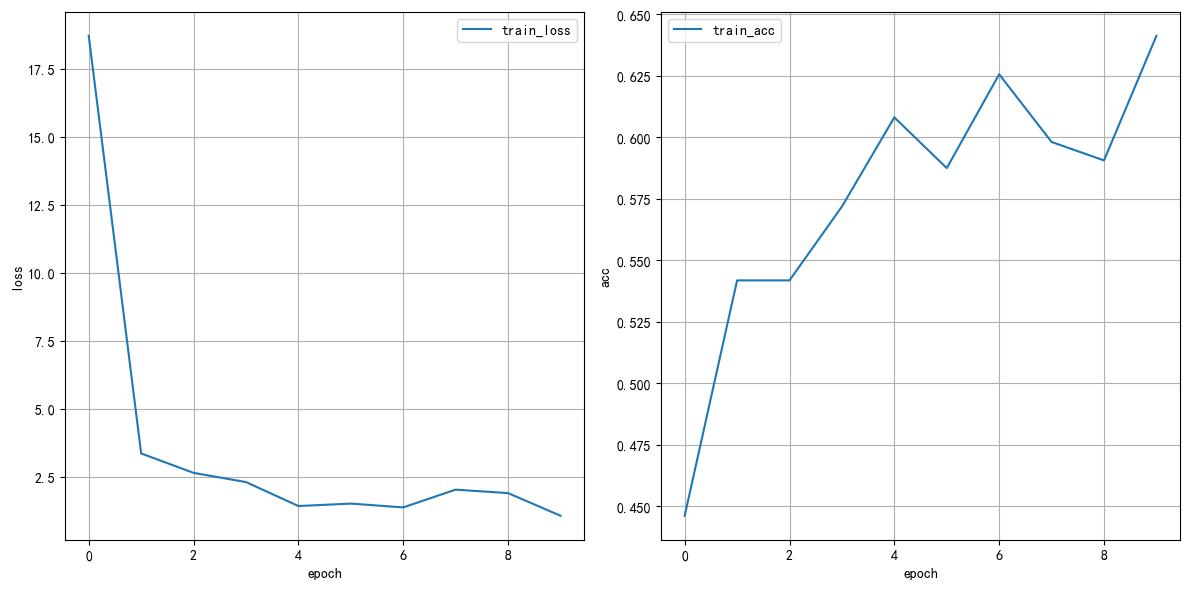

测试损失：1.0181 | 测试准确率：0.6500


In [2]:
"""
演示
    手机价格分类案例
注意：
    这里是预测手机价格区间，0，1，2，3，是一个分类任务，我们用全连接神经网络实现

神经网络训练的工作流
    1.准备数据集
        拆分数据集为训练集和测试集
        numpy数值 -> 张量 -> 数据集对象 -> 数据加载器
    2.搭建神经网络
        使用全连接神经网络
        1.继承nn.Module
        2.定义__init__方法，构造网络层
        3.定义forward方法，前向传播
        细节：网络参数量的计算方法：(输入维度+1)*输出维度
    3.模型训练-在训练集上训练
        前向传播
        计算损失
        梯度清零
        反向传播
        更新参数
    4.模型测试-在测试集上测试

"""
import os

# 导入相关模块
import torch
from torch.utils.data import TensorDataset  # 数据集对象
from torch.utils.data import DataLoader # 数据加载器
import torch.nn as nn   # 神经网络模块，实现各种网络层
import torch.optim as optim # 优化器模块，实现各种优化器，比如SGD,Adam/AdamW
from sklearn.model_selection import train_test_split    # 划分数据集,pip install scikit-learn
import matplotlib.pyplot as plt # pip install matplotlib
import numpy as np  # pip install matplotlib
import pandas as pd # pip install pandas
import time
from torchsummary import summary    # 统计模型参数量
# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei']  # 微软雅黑
plt.rcParams['axes.unicode_minus'] = False            # 解决负号显示问题
# 设置设备，GPU > MPS > CPU
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print(f"当前设备：{device}")

# 设置随机种子
torch.manual_seed(28)

# 1.准备数据集
def create_dataset():
    # 1.加载CSV
    df = pd.read_csv(r"./data/手机价格预测.csv")
    # 2.构造输入特征x,输出标签y
    # 前20列是输入特征，最后一列是标签y
    x = df.iloc[:, :-1]
    y = df.iloc[:, -1]
    # 转换x的元素类型为浮点数float32
    x = x.astype(np.float32)
    # 转换y的元素类型为整数int64
    y = y.astype(np.int64)
    # 3.拆分数据集为训练集和测试集
    # 参数1：输入特征x；参数2：标签y；参数3：训练集拆分比例；参数4：随机状态，固定随机性
    # 参数5：stratify,按哪个标签比例进行层次拆分，比如y中类别比例为1：1：1：1，拆分之后的数据也要符合这个比例
    x_train, x_test, y_train, y_test = train_test_split(x,y,train_size=0.8,random_state=28,stratify=y)
    # 4.numpy数值 -> 张量
    x_train = torch.tensor(x_train.values).to(dtype=torch.float32)
    x_test = torch.tensor(x_test.values).to(dtype=torch.float32)
    y_train = torch.tensor(y_train.values).to(dtype=torch.long)
    y_test = torch.tensor(y_test.values).to(dtype=torch.long)
    # print(f"x_train.shape:{x_train.shape}, x_test.shape:{x_test.shape}, y_train.shape:{y_train.shape}, y_test.shape:{y_test.shape}")
    # 5.张量 -> 数据集对象, 封装输入特征x和输出标签y
    train_dataset = TensorDataset(x_train,y_train)
    test_dataset = TensorDataset(x_test,y_test)
    # 6.返回
    return train_dataset, test_dataset

# 2.搭建神经网络
class MyPhonePriceClassifier(nn.Module):
    # 1.定义__init__方法，构造网络层
    def __init__(self, input_dim=20, output_dim=4):
        # 1.初始化父类成员
        super().__init__()
        # 2.定义第一个线性层
        self.linear1 = nn.Linear(input_dim,256)
        # 3.定义第二个线性层
        self.linear2 = nn.Linear(256,128)
        # 4.定义第三个线性层，输出层
        self.linear3 = nn.Linear(128,output_dim)
    # 2.定义forward方法，前向传播
    def forward(self,x):
        # x:(batch_size,20)
        # 1.数据输入linear1，relu
        x = torch.relu(self.linear1(x)) # (batch_size,256)
        # 2.数据输入linear2,relu
        x = torch.relu(self.linear2(x)) # (batch_size,128)
        # 3.数据输入linear3
        x = self.linear3(x) # (batch_size,4)
        # 4.返回结果
        return x

# 3.模型训练-在训练集上训练
# 3.1 训练一个轮次
def train_one_epoch(model, train_dataloader, loss_fn, optimizer):
    # 1.设置训练模式model.train()
        model.train()
        # 2.初始化 训练的总损失，总样本数，预测正确的样本数
        train_loss = 0.0
        total_samples = 0
        total_correct = 0
        # 获取当前时刻
        start_time = time.time()
        # 3.遍历数据加载器，分批次训练
        for x, y in train_dataloader:
            # x:(batch_size,input_dim)
            # y:(batch_size,)
            # 0.迁移数据到device
            x = x.to(device)
            y = y.to(device)
            # 1.前向传播
            y_pred = model(x)   # (batch_size,4)
            # 2.计算损失
            loss = loss_fn(y_pred,y)
            # print(f"loss:{loss}, shape:{loss.shape}")   # 0D
            # 3.梯度清零
            optimizer.zero_grad()
            # 4.反向传播
            loss.backward()
            # 5.更新参数
            optimizer.step()
            # 6.更新训练指标，训练损失，训练样本数，预测正确的样本数
            batch_size = x.shape[0]
            # 更新训练总损失
            train_loss += loss.item() * batch_size  # 当前批次的总损失=平均损失*当前批次的批次大小
            # 更新训练样本数
            total_samples += batch_size
            # 更新预测正确的样本数
            total_correct += (y_pred.argmax(dim=-1) == y).sum().item()
            ...
        # 4.计算当前轮次的训练损失和训练准确率
        avg_train_loss = train_loss / total_samples
        avg_train_acc = total_correct / total_samples
        # 获取训练损失和准确率
        train_losses.append(avg_train_loss)
        train_accs.append(avg_train_acc)
        end_time = time.time()
        epoch_time = end_time - start_time
        return avg_train_loss, avg_train_acc, epoch_time

# train_dataset:训练集数据集对象
# input_dim:数据的特征维度，20
# output_dim: 输出维度，4，也就是有4个类别
def train(train_dataset, input_dim=20, output_dim=4, epochs=10):
    # 1.创建数据加载器对象
    # 参数1：数据集对象；参数2：批次大小；参数3：是否打乱数据，训练时打乱，测试时不打乱；参数4: 是否删除最后一个不完整的批次数据
    train_dataloader = DataLoader(train_dataset,batch_size=32,shuffle=True,drop_last=False)
    # 2.创建神经网络模型对象
    model = MyPhonePriceClassifier(
        input_dim=input_dim,
        output_dim=output_dim
    )
    # 迁移模型到设备
    model = model.to(device)
    # 3.定义损失函数和优化器
    loss_fn = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(),lr=1e-3)
    # 定义变量，记录 每个轮次的 训练损失 和 准确率
    train_losses = []
    train_accs = []
    # 4.模型训练
    # 遍历轮数epochs
    for epoch in range(epochs):
        # 1.设置训练模式model.train()
        model.train()
        # 2.初始化 训练的总损失，总样本数，预测正确的样本数
        train_loss = 0.0
        total_samples = 0
        total_correct = 0
        # 获取当前时刻
        start_time = time.time()
        # 3.遍历数据加载器，分批次训练
        for x, y in train_dataloader:
            # x:(batch_size,input_dim)
            # y:(batch_size,)
            # 0.迁移数据到device
            x = x.to(device)
            y = y.to(device)
            # 1.前向传播
            y_pred = model(x)   # (batch_size,4)
            # 2.计算损失
            loss = loss_fn(y_pred,y)
            # print(f"loss:{loss}, shape:{loss.shape}")   # 0D
            # 3.梯度清零
            optimizer.zero_grad()
            # 4.反向传播
            loss.backward()
            # 5.更新参数
            optimizer.step()
            # 6.更新训练指标，训练损失，训练样本数，预测正确的样本数
            batch_size = x.shape[0]
            # 更新训练总损失
            train_loss += loss.item() * batch_size  # 当前批次的总损失=平均损失*当前批次的批次大小
            # 更新训练样本数
            total_samples += batch_size
            # 更新预测正确的样本数
            total_correct += (y_pred.argmax(dim=-1) == y).sum().item()
            ...
        # 4.计算当前轮次的训练损失和训练准确率
        avg_train_loss = train_loss / total_samples
        avg_train_acc = total_correct / total_samples
        # 获取训练损失和准确率
        train_losses.append(avg_train_loss)
        train_accs.append(avg_train_acc)
        end_time = time.time()
        epoch_time = end_time - start_time
        # 5.打印训练损失和训练准确率
        print(f"{epoch+1}/{epochs} | "
              f"训练损失：{avg_train_loss:.4f} | "
              f"训练准确率：{avg_train_acc:.4f} | "
              f"训练时间：{epoch_time:.2f}s")
        ...
    # 5.保存模型文件
    # 新建文件夹model
    os.makedirs("model",exist_ok=True)
    # 保存模型参数文件，因为在不同设备上迁移更加方便，如果把模型结构也保存了，那么模型在不同设备上迁移困难
    # print(f"模型参数：{model.state_dict()}")
    torch.save(model.state_dict(),"model/phone_price_classifier.pth")
    # 返回训练损失和训练准确率
    return train_losses, train_accs

# 3.1 可视化训练过程
def plot_train_process(train_losses, train_accs):
    plt.figure(figsize=(12, 6))
    # 绘制训练损失曲线
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, label="train_loss")
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.legend()
    plt.grid(True)
    # plt.show()
    # 绘制训练准确率曲线
    plt.subplot(1, 2, 2)
    plt.plot(train_accs, label="train_acc")
    plt.xlabel("epoch")
    plt.ylabel("acc")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# 4.模型测试-在测试集上测试
# 参数1：测试集
@torch.no_grad()   # 关闭梯度计算
def evaluate(test_dataset, input_dim=20, output_dim=4):
    # 1.创建数据加载器对象
    # 参数1：数据集对象；参数2：批次大小；参数3：是否打乱数据，训练时打乱，测试时不打乱；参数4: 是否删除最后一个不完整的批次数据
    test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False, drop_last=False)
    # 2.创建神经网络模型对象
    model = MyPhonePriceClassifier(
        input_dim=input_dim,
        output_dim=output_dim
    )
    # 迁移模型到设备
    model = model.to(device)
    # 3.加载模型参数，将模型参数文件的模型参数加载到示例化的模型对象中
    model.load_state_dict(torch.load("model/phone_price_classifier.pth"))
    # 定义损失函数
    loss_fn = nn.CrossEntropyLoss()
    # 4.模型测试，设置为评估模式model.eval()，告诉模型，现在是训练/评估，不要开启dropout等特殊网络层
    model.eval()
    # 定义变量，记录测试 的总损失，总样本数，预测正确的样本数
    test_loss = 0.0
    total_samples = 0
    total_correct = 0
    # 遍历批次，也就是遍历数据加载器
    for x, y in test_dataloader:
        # x:(batch_size,input_dim)
        # y:(batch_size,)
        # 0.迁移数据到device
        x = x.to(device)
        y = y.to(device)
        # 1.前向传播
        y_pred = model(x)  # (batch_size,4)
        # 2.计算损失
        loss = loss_fn(y_pred, y)
        # 梯度清零
        # 反向传播
        # 更新参数
        # 3.更新指标，损失，样本数，预测正确的样本数
        batch_size = x.shape[0]
        # 更新总损失
        test_loss += loss.item() * batch_size  # 当前批次的总损失=平均损失*当前批次的批次大小
        # 更新样本数
        total_samples += batch_size
        # 更新预测正确的样本数
        total_correct += (y_pred.argmax(dim=-1) == y).sum().item()
        ...
    # 计算测试损失和测试准确率
    avg_test_loss = test_loss / total_samples
    avg_test_acc = total_correct / total_samples
    # 返回结果
    return avg_test_loss, avg_test_acc

# 测试
if __name__ == "__main__":
    # 1.准备数据集
    train_dataset, test_dataset=create_dataset()
    print(f"训练集数量：{len(train_dataset)}")
    print(f"测试集数量：{len(test_dataset)}")
    print(f"train_dataset:{train_dataset}, test_dataset:{test_dataset}")
    # # 2.创建模型对象
    # model = MyPhonePriceClassifier()    # 默认模型对象在CPU上
    # model = model.to(device)    # 将模型对象移动到device上，比如GPU
    # print(model)
    # summary(model, input_size=(20,))
    # 3.模型训练
    train_losses, train_accs=train(train_dataset, input_dim=20, output_dim=4, epochs=10)
    # 可视化训练过程
    plot_train_process(train_losses, train_accs)
    # 4.模型测试
    avg_test_loss, avg_test_acc = evaluate(test_dataset, input_dim=20, output_dim=4)
    print(f"测试损失：{avg_test_loss:.4f} | 测试准确率：{avg_test_acc:.4f}")

- 模型优化
1. 对输入数据进行标准化
2. 调整优化器
3. 调整学习率
4. 增加批量归一化层BN1D
5. 增加网络层数、神经元个数
6. 增加训练轮数
7. 使用GPU加速训练
8. 等等...

使用设备：cuda
train_dataset: <torch.utils.data.dataset.TensorDataset object at 0x0000020A32943750>
test_dataset: <torch.utils.data.dataset.TensorDataset object at 0x00000207CE41D220>
input_dim: 20
output_dim: 4
epoch: 0, loss: 0.4223148721456528, acc: 0.835625, time: 0.17
epoch: 1, loss: 0.2680707371234894, acc: 0.88875, time: 0.08
epoch: 2, loss: 0.30456461310386657, acc: 0.86875, time: 0.07
epoch: 3, loss: 0.24829048722982405, acc: 0.900625, time: 0.06
epoch: 4, loss: 0.22864936500787736, acc: 0.905625, time: 0.06
epoch: 5, loss: 0.3206814354658127, acc: 0.874375, time: 0.07
epoch: 6, loss: 0.2578844326734543, acc: 0.895625, time: 0.06
epoch: 7, loss: 0.2961209285259247, acc: 0.86875, time: 0.06
epoch: 8, loss: 0.23129419028759002, acc: 0.905625, time: 0.06
epoch: 9, loss: 0.2255326974391937, acc: 0.9025, time: 0.07
epoch: 10, loss: 0.2340228545665741, acc: 0.9025, time: 0.07
epoch: 11, loss: 0.22033088743686677, acc: 0.905625, time: 0.06
epoch: 12, loss: 0.26610502690076826, acc: 0.8887

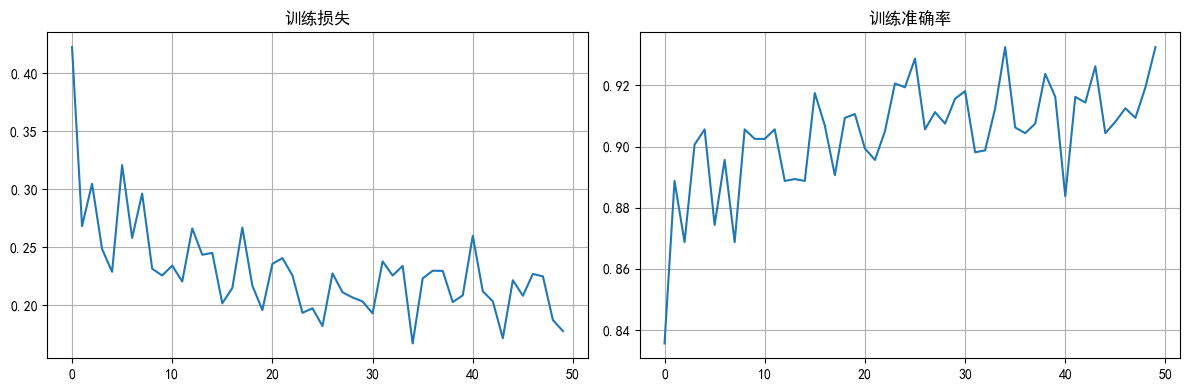

测试集准确率：0.965


In [7]:
import torch  # pytorch框架
from torch.utils.data import TensorDataset  # 数据集对象
from torch.utils.data import DataLoader  # 数据加载器
import torch.nn as nn  # 神经网络层的操作
import torch.optim as optim  # 优化器
from sklearn.model_selection import train_test_split  # 拆分 训练集 和 测试集
import matplotlib.pyplot as plt  # 绘图
import numpy as np  # 数组操作
import pandas as pd  # 数据处理
import time  # 时间模块

from torchsummary import summary
from sklearn.preprocessing import StandardScaler
# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei']  # 微软雅黑
plt.rcParams['axes.unicode_minus'] = False            # 解决负号显示问题
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"使用设备：{device}")

# 1.准备数据集
def create_dataset():
    # 1.加载CSV数据集
    data = pd.read_csv("./data/手机价格预测.csv")
    # 2.获取特征x 和 标签y
    x = data.iloc[:, :-1]
    y = data.iloc[:, -1]

    # 3.特征列 转换为 float
    x = x.astype(np.float32)

    # 4.拆分数据集
    x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=6, stratify=y)

    # 数据标准化
    # scaler = StandardScaler()
    # x_train = scaler.fit_transform(x_train)
    # x_test = scaler.transform(x_test)
    # 5.把数据集转换为张量, numpy数组 -> 张量 -> 数据集对象TensorDataset -> 数据加载器DataLoader
    train_dataset = TensorDataset(torch.tensor(x_train.values), torch.tensor(y_train.values))
    test_dataset = TensorDataset(torch.tensor(x_test.values), torch.tensor(y_test.values))

    # 6.返回结果
    return train_dataset, test_dataset, x_train.shape[1], len(y_train.unique())

# 2.搭建神经网络
class PhonePriceClassifier(nn.Module):
    # 1.定义__init__方法, 初始化父类成员，搭建神经网络
    def __init__(self, input_dim, output_dim):
        # 初始化父类成员
        super().__init__()
        # 搭建神经网络
        # 优化1：增加网络深度+使用BN1D层
        self.linear1 = nn.Linear(input_dim, 512)
        self.bn1 = nn.BatchNorm1d(512)
        self.linear2 = nn.Linear(512, 512)
        self.bn2 = nn.BatchNorm1d(512)
        self.linear3 = nn.Linear(512, 256)
        self.bn3 = nn.BatchNorm1d(256)
        self.linear4 = nn.Linear(256, output_dim)
        self.dropout = nn.Dropout(0.1)

    # 2.定义forward方法，实现前向传播
    def forward(self, x):
        # 隐藏层1, linear -> BN层 -> 激活函数 -> dropout
        x = torch.relu(self.bn1(self.linear1(x)))
        x = self.dropout(x)
        # 隐藏层2
        x = torch.relu(self.bn2(self.linear2(x)))
        x = self.dropout(x)
        x = torch.relu(self.bn3(self.linear3(x)))
        x = self.dropout(x)
        # 输出层
        x = self.linear4(x)
        # 返回结果
        return x


# 3.模型训练
def train(train_dataset, input_dim, output_dim):
    # 1.创建数据加载器DataLoader
    # 参数1：数据集对象；参数2：批量大小；参数3：是否打乱数据
    train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
    # 2.创建神经网络模型
    model = PhonePriceClassifier(input_dim, output_dim)
    model.to(device)
    # 3.定义损失函数
    loss_fn = nn.CrossEntropyLoss()
    # 4.创建优化器对象
    # 优化3：使用Adam优化方法
    optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
    # 优化4：添加学习率调度，optim.lr_scheduler.CosineAnnealingWarmRestarts
    scheduler = optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=5*len(train_loader), T_mult=1)
    # 5.模型训练
    # 定义变量，记录 训练总轮数
    epochs = 50
    # 定义遍历，记录每轮次的损失和准确率
    train_losses = []
    train_accs = []
    # 遍历轮数
    for epoch in range(epochs):
        # 记录 每次训练的 损失值，训练样本数，预测正确的样本数
        total_loss = 0.
        total_sample = 0
        total_correct = 0
        # 记录训练开始时间
        start_time = time.time()
        # 遍历批次
        for x, y in train_loader:
            # 训练模式
            model.train()
            # 移动数据到GPU
            x = x.to(device)
            y = y.to(device)
            # 前向传播
            y_pred = model(x)
            # 计算损失值
            loss = loss_fn(y_pred, y)
            # 更新总损失
            batch_size = x.shape[0]
            total_loss += loss.item() * batch_size
            # 更新总样本数
            total_sample += batch_size
            # 更新预测正确的样本数
            total_correct += (torch.argmax(y_pred, dim=-1) == y).sum().item()
            # 梯度清零
            optimizer.zero_grad()
            # 反向传播
            loss.backward()
            # 更新参数
            optimizer.step()
            scheduler.step()

        # 打印训练信息
        print(
            f"epoch: {epoch}, loss: {total_loss / total_sample}, acc: {total_correct / total_sample}, time: {time.time() - start_time:.2f}")
        train_losses.append(total_loss / total_sample)
        train_accs.append(total_correct / total_sample)
    # 6.保存模型参数
    # print(f"\n\n模型的参数信息: {model.state_dict()}\n\n")
    torch.save(model.state_dict(), "./model/phone_price_classifier.pth")  # 模型文件，后缀名 .pth, .pkl, .pickle 均可
    # 7.返回训练结果
    return train_losses, train_accs

# 可视化训练过程
def plot_train_process(train_losses, train_accs):
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(train_losses)
    plt.title("训练损失")
    plt.grid(True)
    plt.subplot(1, 2, 2)
    plt.plot(train_accs)
    plt.title("训练准确率")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# 4.模型测试
@torch.no_grad()
def evaluate(test_dataset, input_dim, output_dim):
    # 1. 创建神经网络分类对象.
    model = PhonePriceClassifier(input_dim, output_dim)
    model.to(device)
    # 2.加载模型参数
    model.load_state_dict(torch.load('./model/phone_price_classifier.pth'))
    # 3.创建数据加载器DataLoader
    # 参数1：数据集对象；参数2：批量大小；参数3：是否打乱数据
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
    # 4.记录正确样本的数量
    correct_sample = 0
    total_sample = 0
    # 5.开始测试, 遍历数据加载器的批次数据
    for x, y in test_loader:
        # 切换到测试模式
        model.eval()
        # 张量 迁移 到 GPU
        x = x.to(device)
        y = y.to(device)
        # 6.前向传播，模型预测
        y_pred = model(x)  # 形状(batch_size, 4), 每个类别的输出logits
        # print(f"预测结果y_pred：{y_pred}")
        # 7.计算预测正确的数量
        correct = y_pred.argmax(dim=1) == y
        correct_sample += correct.sum().item()
        total_sample += y.size(0)
    print(f"测试集准确率：{correct_sample / total_sample}")


# 5.测试
if __name__ == '__main__':
    # 1.准备数据集
    train_dataset, test_dataset, input_dim, output_dim = create_dataset()
    # 打印
    print(f"train_dataset: {train_dataset}")
    print(f"test_dataset: {test_dataset}")
    print(f"input_dim: {input_dim}")
    print(f"output_dim: {output_dim}")
    # 2.构建神经网络
    model = PhonePriceClassifier(input_dim, output_dim)
    # 3.统计模型参数
    model.to(device)
    # summary(model,input_size=(input_dim,))
    # 4.模型训练
    train_losses, train_accs = train(train_dataset, input_dim, output_dim)
    plot_train_process(train_losses, train_accs)
    # 5.模型测试
    evaluate(test_dataset, input_dim, output_dim)

## 常见面试题

### 1. 常见的学习率衰减策略 或 学习率调度策略 有哪些？
- 等间隔衰减：每隔固定训练轮次，将学习率乘以一个固定比例
- 余弦退火：学习率按余弦曲线平滑下降，可周期性重启来跳出局部最优解。
- 自适应学习率：根据梯度自动调整学习率，如 Adam、RMSProp
- 其他
  - 指定间隔衰减：指定间隔衰减学习率
  - 指数衰减：学习率按指数连续衰减

---

### 2. 常用的正则化方法有哪些？
- L1/L2正则化：L1惩罚权重绝对值，L2惩罚权重的平方。
- dropout：训练时随机失活神经元，防止过拟合。
- 批量归一化：标准化输入数据，减小数据分布偏差。
---

### 3. 简述dropout的计算原理？
- 训练时，dropout**让神经元以随机概率p 随机失活，将输出置为0, 其余输出 /(1-p)**。
- 测试时，dropout随机失活不起作用。

---
### 4. dropout训练时为什么要将输出/(1-p)？
- Dropout以概率p让神经元随机失活，将输出置为0，会使得输出的期望变为原始期望*(1-p)，
- 为了保持 训练 和 预测 时的数值一致性，Dropout之后需要/(1-p)，缩放为原始期望

---

### 5. 简述BN批量归一化的计算原理？
  批量归一化在训练时，先对数据标准化，再进行 缩放+平移，从而减小数据分布的偏差。
  - 训练时，BN层先将数据标准化为均值0，方差1的分布，然后进行缩放和平移，同时还会维护一个全局均值和全局方差，用于测试时进行归一化。
  - 测试时，BN层使用训练时的全局均值和方差先对数据进行标准化，然后使用训练时的缩放和平移参数进行缩放和平移。
  - 缩放参数和平移参数是在训练过程中学习的。

---
### 6. 简述神经网络训练的一般工作流？
- 1.准备数据集
- 2.搭建神经网络模型
- 3.模型训练
    1. 前向传播：$\hat{y} = model(X)$
    2. 计算损失：$loss = loss\_fn(\hat{y}, y)$
    3. 梯度清零：$optimizer.zero\_grad()$
    4. 反向传播：$loss.backward()$
    5. 更新参数：$optimizer.step()$
- 4.模型测试

---

### 7. 神经网络训练中，如何避免或缓解梯度爆炸或者梯度消失？
  - 梯度爆炸
    - 1. 降低学习率  
    - 2. 合理参数初始化方法（Kaiming / Xavier）  
    - 3. 使用稳定激活函数（ReLU / Leaky ReLU）  
    - 4. 使用批归一化（BatchNorm）改善输入分布  
    - 5. 梯度裁剪

  - 梯度消失
    - 1. 非饱和激活函数（ReLU）  
    - 2. 合理参数初始化方法（Kaiming / Xavier）  
    - 3. 批量归一化（BatchNorm）  
    - 4. 残差或跳跃连接（ResNet / DenseNet）  


## 代码作业

- 1.使用两层dropout处理数据。输入数据形状为(2,4),隐藏层形状为(4,20),后接dropout(p=0.5),输出层形状为(20,10),得到输出结果，并打印。注意通常输出层之后不加dropout
- 2.修改手机价格分类案例代码。采用周期启动的余弦退火学习率调度策略torch.optim.lr_scheduler.CosineAnnealingWarmRestarts来调整学习率，训练模型，并打印最终的测试准确率。
- 3.修改手机价格分类案例代码。模型中添加dropout层，优化器改为AdamW, 采用周期启动的余弦退火学习率调度策略torch.optim.lr_scheduler.CosineAnnealingWarmRestarts来调整学习率，训练模型，并打印最终的测试准确率。注意dropout的p应该小于0.1，因为数据集较小。

## 扩展-L1正则化如何导致权重稀疏性

| 方法类型 | 核心公式 | 权重逼近0的效果 | PyTorch 实现方式 |
|---|---|---|---|
| **L1 Loss (MAE)** | $L = \frac{1}{N}\sum \|y_i - \hat{y}_i\|$ | 仅拟合目标值，不约束权重 | `nn.L1Loss()` |
| **L2 Loss (MSE)** | $L = \frac{1}{N}\sum (y_i - \hat{y}_i)^2$ | 仅拟合目标值，不约束权重 | `nn.MSELoss()` |
| **L1 正则化** | $Loss = L_{data} + \lambda \sum \|w\|$ | 促使权重趋近0，但普通梯度下降难以精确为0 | 手动计算：`loss += lambda * sum(w.abs().sum())` |
| **L1 正则化 + 软阈值** | $w = \text{sign}(w) \max(\|w\| - \lambda \eta, 0)$ | **强制将较小权重精确归零，产生稀疏性** | 梯度更新后执行：`w = torch.sign(w) * torch.clamp(torch.abs(w) - threshold, min=0.0)` |

### 核心要点
1. **L1 Loss / MSE Loss**: 衡量预测值与真实值的误差，不直接影响权重的稀疏性。
2. **L1 正则化 (L1 Regularization)**: 作为惩罚项加在损失函数中，能促使权重变小，但在标准梯度下降中很难让权重精确等于0。
3. **软阈值 (Soft Thresholding)**: 结合 L1 正则化使用的非梯度优化操作，是实现权重**精确归零（稀疏性）**的关键机制。通常所说的“L1正则化产生稀疏性”，在具体优化算法（如近端梯度下降 PGD）中均通过类似软阈值的操作实现。
4. **神经网络项目中，主要使用L2正则化**

### 面试回答
**问题**：L1正则化是如何导致权重稀疏性的？

**回答**：L1正则化通过在损失函数中添加权重绝对值，促使模型倾向于将不重要的权重减小到接近0。虽然标准梯度下降难以让权重精确为0，但结合软阈值操作可以强制将较小的权重直接归零，从而实现稀疏性。使得L1正则化适合特征选择和模型压缩等场景。

**问题**：L1正则化与L2正则化的区别是什么？

**回答**：L1 能产生稀疏权重（可变为 0），用于特征选择；L2 不会稀疏，只让权重均匀变小，训练更稳定，是深度学习主流。

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

# 1. 定义简单模型
class SimpleModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(100, 1)  # 100个输入权重
    
    def forward(self, x):
        return self.linear(x)

# 2. 初始化组件（仅微调λ和lr）
model = SimpleModel()
optimizer = optim.AdamW(model.parameters(), lr=0.1, weight_decay=0)  # L2正则化通过weight_decay实现，L1通过手动添加惩罚项实现
lambda_l1 = 0.1  # L1惩罚系数

# 3. 固定训练数据
x_fixed = torch.ones(32, 100)  # 输入全为1
y_fixed = torch.zeros(32, 1)

# 4. 训练过程
def train(loss_fn, l1_penalty=False, is_threshold=False, optimizer=optimizer, model=model, x_fixed=x_fixed, y_fixed=y_fixed, lambda_l1=lambda_l1):
    model.train()
    for epoch in range(1000):
        # 前向传播
        y_pred = model(x_fixed)
        loss1 = loss_fn(y_pred, y_fixed)
        
        # 计算L1惩罚项
        l1_penalty = torch.tensor(0., requires_grad=True)
        for param in model.parameters():
            l1_penalty = l1_penalty + torch.sum(torch.abs(param))
        
        # 总损失
        total_loss = loss1
        if l1_penalty:
            total_loss += lambda_l1 * l1_penalty
        
        # 反向传播
        optimizer.zero_grad()
        total_loss.backward()
        optimizer.step()

        # ========== 软阈值操作 ==========
        if is_threshold:
            threshold = 0.001 
            with torch.no_grad():  # 不追踪梯度，避免影响反向传播
                for param in model.parameters():
                    # 软阈值公式：强制权重精确归零
                    param.data = torch.sign(param.data) * torch.clamp(
                        torch.abs(param.data) - threshold, 
                        min=0.0  # 小于阈值的权重直接置0
                    )
    return model

# 5. 验证稀疏性
def get_sparsity(model):
    weight = model.linear.weight.data.squeeze()  # 转为1维张量
    print("线性层权重具体值（前10个示例）：")
    print(weight[:10].numpy())
    zero_count = (weight == 0).sum().item()  # 直接判断是否精确等于0
    total_count = weight.numel()
    sparsity_ratio = zero_count / total_count
    print(f"权重总数量：{total_count}")
    print(f"零值权重数量（精确等于0）：{zero_count}")
    print(f"权重稀疏度：{sparsity_ratio:.4f}")
    return total_count, zero_count, sparsity_ratio

# 6.验证损失函数的稀疏性
# 验证MAE损失的稀疏性
loss_mae = nn.L1Loss()
print("\n=== MAE损失 ===")
model = train(loss_mae, l1_penalty=False, is_threshold=False, optimizer=optimizer, model=model, x_fixed=x_fixed, y_fixed=y_fixed, lambda_l1=lambda_l1)
total_count, zero_count, sparsity_ratio = get_sparsity(model)
# 验证MSE损失的稀疏性
loss_mse = nn.MSELoss()
print("\n=== MSE损失 ===")
model = train(loss_mse, l1_penalty=False, is_threshold=False, optimizer=optimizer, model=model, x_fixed=x_fixed, y_fixed=y_fixed, lambda_l1=lambda_l1)
total_count, zero_count, sparsity_ratio = get_sparsity(model)

# 7.验证L1/L2正则化的稀疏性
# 验证L1正则化的稀疏性
print("\n=== MSE + L1正则化 ===")
model = train(loss_mse, l1_penalty=True, is_threshold=False, optimizer=optimizer, model=model, x_fixed=x_fixed, y_fixed=y_fixed, lambda_l1=lambda_l1)
total_count, zero_count, sparsity_ratio = get_sparsity(model)
# 验证L2正则化的稀疏性
print("\n=== MSE + L2正则化(通过AdamW的weight_decay实现) ===")
optimizer_l2 = optim.AdamW(model.parameters(), lr=0.01, weight_decay=0.01)  # L2正则化通过weight_decay实现
model = train(loss_mse, l1_penalty=False, is_threshold=False, optimizer=optimizer_l2, model=model, x_fixed=x_fixed, y_fixed=y_fixed, lambda_l1=lambda_l1)
total_count, zero_count, sparsity_ratio = get_sparsity(model)
# 验证L1正则化 + 软阈值的稀疏性
print("\n=== MSE + L1正则化 + 软阈值 ===")
model = train(loss_mse, l1_penalty=True, is_threshold=True, optimizer=optimizer, model=model, x_fixed=x_fixed, y_fixed=y_fixed, lambda_l1=lambda_l1)
total_count, zero_count, sparsity_ratio = get_sparsity(model)
# 验证L2正则化 + 软阈值的稀疏性
print("\n=== MSE + L2正则化 + 软阈值 ===")
optimizer_l2 = optim.AdamW(model.parameters(), lr=0.01, weight_decay=0.01)  # L2正则化通过weight_decay实现
model = train(loss_mse, l1_penalty=False, is_threshold=True, optimizer=optimizer_l2, model=model, x_fixed=x_fixed, y_fixed=y_fixed, lambda_l1=lambda_l1)
total_count, zero_count, sparsity_ratio = get_sparsity(model)


=== MAE损失 ===
线性层权重具体值（前10个示例）：
[-0.00862327 -0.01270206 -0.01293416 -0.01426165 -0.00622941 -0.01625468
 -0.01781615 -0.01165615 -0.01171495 -0.01886621]
权重总数量：100
零值权重数量（精确等于0）：0
权重稀疏度：0.0000

=== MSE损失 ===
线性层权重具体值（前10个示例）：
[-0.00261043 -0.00342005 -0.00301043  0.00375149 -0.00294614  0.00085483
  0.00568072 -0.00105823  0.00243323 -0.00079194]
权重总数量：100
零值权重数量（精确等于0）：0
权重稀疏度：0.0000

=== MSE + L1正则化 ===
线性层权重具体值（前10个示例）：
[0.00398447 0.00020162 0.00263524 0.00291217 0.00205625 0.00296336
 0.00169305 0.00066617 0.00066049 0.00458193]
权重总数量：100
零值权重数量（精确等于0）：0
权重稀疏度：0.0000

=== MSE + L2正则化(通过AdamW的weight_decay实现) ===
线性层权重具体值（前10个示例）：
[-0.00088578 -0.00034875 -0.00086707  0.00127782 -0.00024116  0.00123706
  0.00011647  0.00113909  0.00167758 -0.00116249]
权重总数量：100
零值权重数量（精确等于0）：0
权重稀疏度：0.0000

=== MSE + L1正则化 + 软阈值 ===
线性层权重具体值（前10个示例）：
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
权重总数量：100
零值权重数量（精确等于0）：100
权重稀疏度：1.0000

=== MSE + L2正则化 + 软阈值 ===
线性层权重具体值（前10个示例）：
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]